# Hospital stay prediction
* Predict the expected length-of-stay category for a patient using the information available about the hospital and admission.

## 1.Load the Data

In [28]:
import pandas as pd
import numpy as np

df = pd.read_csv("HealthCareAnalytics.csv")

## 2.Basic checks

In [29]:
df.head()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
0,1,8,c,3,Z,3,radiotherapy,R,F,2.0,31397,7.0,Emergency,Extreme,2,51-60,4911,0-10
1,2,2,c,5,Z,2,radiotherapy,S,F,2.0,31397,7.0,Trauma,Extreme,2,51-60,5954,41-50
2,3,10,e,1,X,2,anesthesia,S,E,2.0,31397,7.0,Trauma,Extreme,2,51-60,4745,31-40
3,4,26,b,2,Y,2,radiotherapy,R,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,7272,41-50
4,5,26,b,2,Y,2,radiotherapy,S,D,2.0,31397,7.0,Trauma,Extreme,2,51-60,5558,41-50


In [30]:
df.tail()

,case_id,Hospital_code,Hospital_type_code,City_Code_Hospital,Hospital_region_code,Available_Extra_Rooms_in_Hospital,Department,Ward_Type,Ward_Facility_Code,Bed_Grade,patientid,City_Code_Patient,Type_of_Admission,Severity_of_Illness,Visitors_with_Patient,Age,Admission_Deposit,Stay
318433,318434,6,a,6,X,3,radiotherapy,Q,F,4.0,86499,23.0,Emergency,Moderate,3,41-50,4144,Nov-20
318434,318435,24,a,1,X,2,anesthesia,Q,E,4.0,325,8.0,Urgent,Moderate,4,81-90,6699,31-40
318435,318436,7,a,4,X,3,gynecology,R,F,4.0,125235,10.0,Emergency,Minor,3,71-80,4235,Nov-20
318436,318437,11,b,2,Y,3,anesthesia,Q,D,3.0,91081,8.0,Trauma,Minor,5,Nov-20,3761,Nov-20
318437,318438,19,a,7,Y,5,gynecology,Q,C,2.0,21641,8.0,Emergency,Minor,2,Nov-20,4752,0-10


In [31]:
df.shape

(318438, 18)

In [32]:
df.dtypes

case_id                                int64
Hospital_code                          int64
Hospital_type_code                    object
City_Code_Hospital                     int64
Hospital_region_code                  object
Available_Extra_Rooms_in_Hospital      int64
Department                            object
Ward_Type                             object
Ward_Facility_Code                    object
Bed_Grade                            float64
patientid                              int64
City_Code_Patient                    float64
Type_of_Admission                     object
Severity_of_Illness                   object
Visitors_with_Patient                  int64
Age                                   object
Admission_Deposit                      int64
Stay                                  object
dtype: object

In [33]:
df.isnull().sum()

case_id                                 0
Hospital_code                           0
Hospital_type_code                      0
City_Code_Hospital                      0
Hospital_region_code                    0
Available_Extra_Rooms_in_Hospital       0
Department                              0
Ward_Type                               0
Ward_Facility_Code                      0
Bed_Grade                             113
patientid                               0
City_Code_Patient                    4532
Type_of_Admission                       0
Severity_of_Illness                     0
Visitors_with_Patient                   0
Age                                     0
Admission_Deposit                       0
Stay                                    0
dtype: int64

In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
df.nunique()

case_id                              318438
Hospital_code                            32
Hospital_type_code                        7
City_Code_Hospital                       11
Hospital_region_code                      3
Available_Extra_Rooms_in_Hospital        18
Department                                5
Ward_Type                                 6
Ward_Facility_Code                        6
Bed_Grade                                 4
patientid                             92017
City_Code_Patient                        37
Type_of_Admission                         3
Severity_of_Illness                       3
Visitors_with_Patient                    28
Age                                      10
Admission_Deposit                      7300
Stay                                     11
dtype: int64

In [36]:
df["Stay"].value_counts()

Stay
21-30                 87491
Nov-20                78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64

## Data-quality issue:

The target currently contains Nov-20, which appears to represent the 11-20 day interval.

In [37]:
df["Stay"] = df["Stay"].replace({"Nov-20": "11-20"})

print(df["Stay"].value_counts())

Stay
21-30                 87491
11-20                 78139
31-40                 55159
51-60                 35018
0-10                  23604
41-50                 11743
71-80                 10254
More than 100 Days     6683
81-90                  4838
91-100                 2765
61-70                  2744
Name: count, dtype: int64


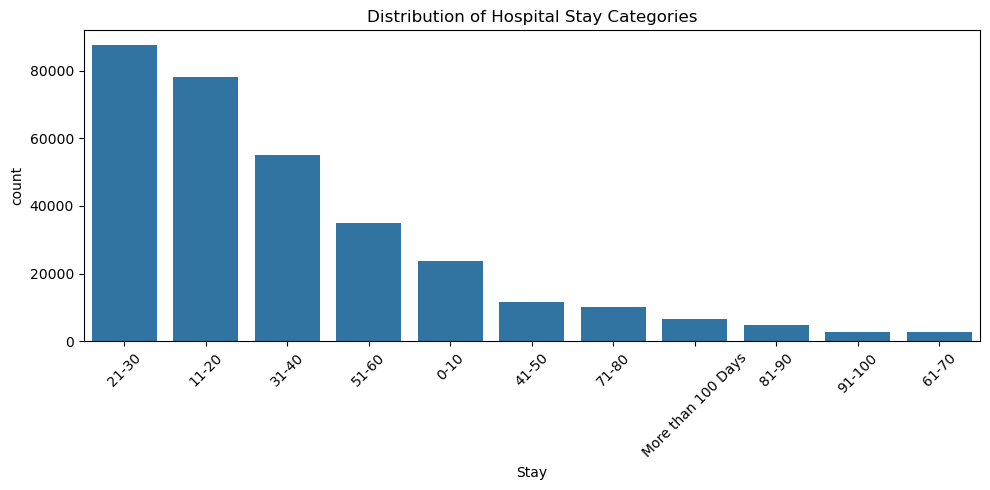

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# Target distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Stay", order=df["Stay"].value_counts().index)
plt.xticks(rotation=45)
plt.title("Distribution of Hospital Stay Categories")
plt.tight_layout()
plt.show()

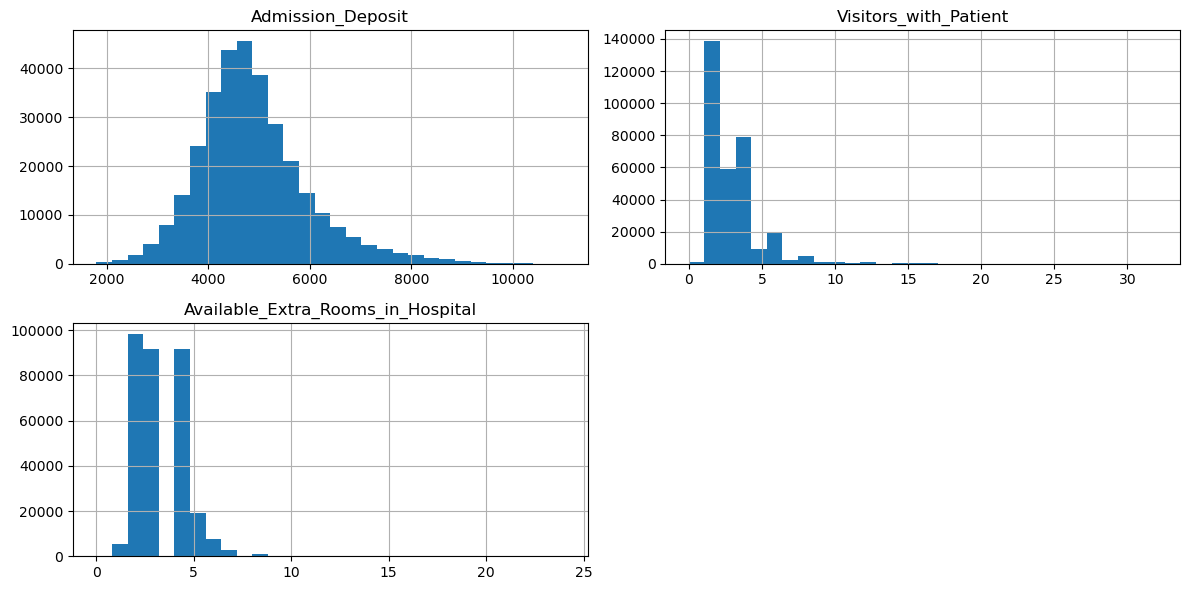

In [39]:
# Numerical distributions
df[["Admission_Deposit",
    "Visitors_with_Patient",
    "Available_Extra_Rooms_in_Hospital"]].hist(
        figsize=(12, 6), bins=30
    )
plt.tight_layout()
plt.show()

In [40]:

print(df["Severity_of_Illness"].value_counts())
print(df["Department"].value_counts())
print(df["Age"].value_counts())

Severity_of_Illness
Moderate    175843
Minor        85872
Extreme      56723
Name: count, dtype: int64
Department
gynecology            249486
anesthesia             29649
radiotherapy           28516
TB & Chest disease      9586
surgery                 1201
Name: count, dtype: int64
Age
41-50     63749
31-40     63639
51-60     48514
21-30     40843
71-80     35792
61-70     33687
Nov-20    16768
81-90      7890
0-10       6254
91-100     1302
Name: count, dtype: int64


## 4. Explore correlations

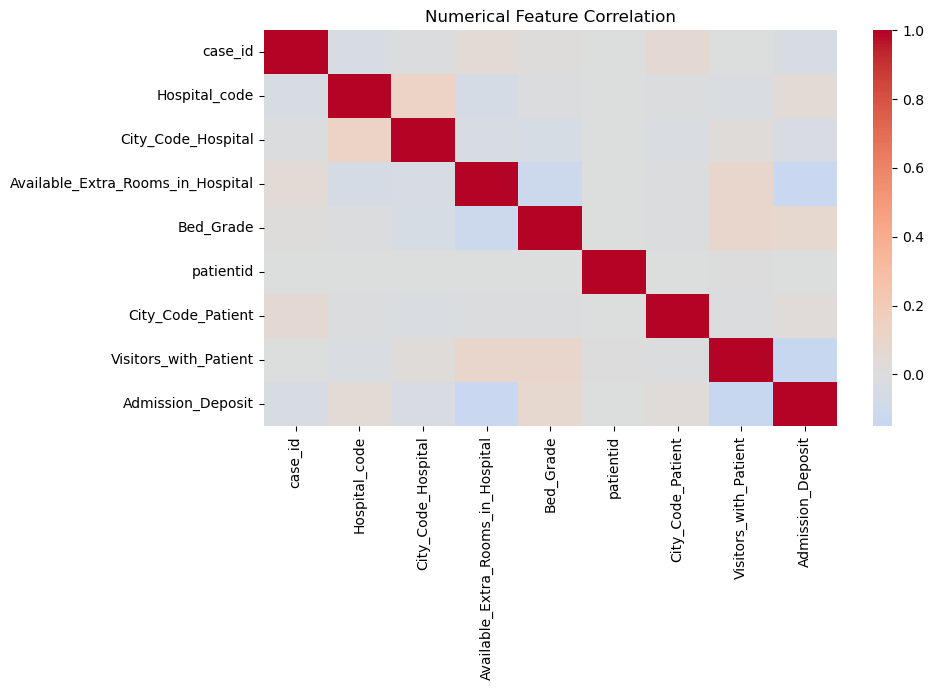

In [41]:
num_cols = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(10, 7))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0)
plt.title("Numerical Feature Correlation")
plt.tight_layout()
plt.show()

## 5.Model creation (fit)

* Split the data into training and test sets. Use stratification to preserve the distribution of stay categories.

In [42]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Normalize the apparent 11-20 target label
df["Stay"] = df["Stay"].replace({"Nov-20": "11-20"})

# Separate target and predictors
X = df.drop(columns=["Stay", "case_id", "patientid"])
y = df["Stay"]

# Treat code-like and text columns as categorical
cat_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

cat_cols += [
    c for c in [
        "Hospital_code",
        "City_Code_Hospital",
        "Bed_Grade",
        "City_Code_Patient"
    ] if c in X.columns
]

cat_cols = list(dict.fromkeys(cat_cols))
num_cols = [c for c in X.columns if c not in cat_cols]

# Preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("categorical", categorical_pipeline, cat_cols),
    ("numerical", numerical_pipeline, num_cols)
])

# Model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit the model
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


## 6. Model evaluation (predict and score)

In [43]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(
    y_test, y_pred, average="macro"
))
print("Weighted F1:", f1_score(
    y_test, y_pred, average="weighted"
))

print(classification_report(
    y_test, y_pred, zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test, y_pred, labels=model.classes_
))

Accuracy: 0.26306368546664993
Macro F1: 0.2093783501242258
Weighted F1: 0.2833582488000355
                    precision    recall  f1-score   support

              0-10       0.20      0.53      0.29      4721
             11-20       0.45      0.29      0.36     15628
             21-30       0.49      0.30      0.37     17498
             31-40       0.29      0.09      0.14     11032
             41-50       0.07      0.20      0.11      2349
             51-60       0.35      0.23      0.28      7004
             61-70       0.02      0.21      0.03       549
             71-80       0.14      0.09      0.11      2051
             81-90       0.11      0.29      0.16       967
            91-100       0.05      0.26      0.08       553
More than 100 Days       0.32      0.49      0.39      1336

          accuracy                           0.26     63688
         macro avg       0.23      0.27      0.21     63688
      weighted avg       0.36      0.26      0.28     63688

Confus

## 7. Hyperparameter tuning

In [44]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_

print("Best parameters:", grid.best_params_)
print("Best CV macro F1:", grid.best_score_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best CV macro F1: 0.2084075962126053


## 8.Final model evaluation

Final Test Accuracy: 0.263597537997739
Final Test Macro F1: 0.20964055037451604
Final Test Weighted F1: 0.2835391255108582
                    precision    recall  f1-score   support

              0-10       0.20      0.53      0.29      4721
             11-20       0.45      0.29      0.36     15628
             21-30       0.49      0.30      0.37     17498
             31-40       0.29      0.09      0.14     11032
             41-50       0.07      0.20      0.11      2349
             51-60       0.34      0.23      0.28      7004
             61-70       0.02      0.20      0.03       549
             71-80       0.14      0.09      0.11      2051
             81-90       0.11      0.30      0.16       967
            91-100       0.05      0.27      0.08       553
More than 100 Days       0.32      0.49      0.39      1336

          accuracy                           0.26     63688
         macro avg       0.23      0.27      0.21     63688
      weighted avg       0.36      

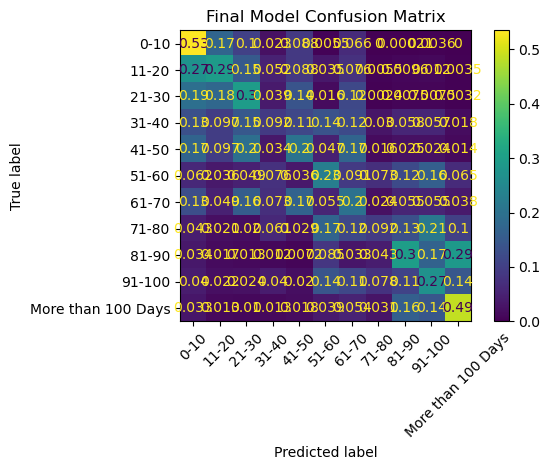

In [45]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred_final = best_model.predict(X_test)

print("Final Test Accuracy:",
      accuracy_score(y_test, y_pred_final))

print("Final Test Macro F1:",
      f1_score(y_test, y_pred_final, average="macro"))

print("Final Test Weighted F1:",
      f1_score(y_test, y_pred_final, average="weighted"))

print(classification_report(
    y_test, y_pred_final, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final,
    labels=best_model.classes_,
    xticks_rotation=45,
    normalize="true"
)
plt.title("Final Model Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Model deployment

In [46]:
import joblib

joblib.dump(best_model, "healthcare_stay_model.pkl")

# Load the saved pipeline
loaded_model = joblib.load("healthcare_stay_model.pkl")

# Example: predict the stay category for an existing record
sample_patient = X_test.iloc[[0]]
predicted_stay = loaded_model.predict(sample_patient)

print("Predicted stay category:", predicted_stay[0])

Predicted stay category: 0-10


## 10. Example of model deployment

In [47]:
import pandas as pd
import joblib

# Load the deployed model
model = joblib.load("healthcare_stay_model.pkl")

# Enter new patient details
new_patient = pd.DataFrame({
    "Hospital_code": [8],
    "Hospital_type_code": ["c"],
    "City_Code_Hospital": [3],
    "Hospital_region_code": ["X"],
    "Available_Extra_Rooms_in_Hospital": [2],
    "Department": ["gynecology"],
    "Ward_Type": ["R"],
    "Ward_Facility_Code": ["F"],
    "Bed_Grade": [2],
    "City_Code_Patient": [7],
    "Type_of_Admission": ["Emergency"],
    "Severity_of_Illness": ["Moderate"],
    "Visitors_with_Patient": [2],
    "Age": ["31-40"],
    "Admission_Deposit": [5000]
})

# Predict hospital stay
prediction = model.predict(new_patient)

# Display result
print("================================")
print("   HEALTHCARE STAY PREDICTION")
print("================================")
print("Patient Details:")
print(new_patient)
print("\nPredicted Hospital Stay:", prediction[0])
print("================================")

   HEALTHCARE STAY PREDICTION
Patient Details:
   Hospital_code Hospital_type_code  City_Code_Hospital Hospital_region_code  \
0              8                  c                   3                    X   

   Available_Extra_Rooms_in_Hospital  Department Ward_Type Ward_Facility_Code  \
0                                  2  gynecology         R                  F   

   Bed_Grade  City_Code_Patient Type_of_Admission Severity_of_Illness  \
0          2                  7         Emergency            Moderate   

   Visitors_with_Patient    Age  Admission_Deposit  
0                      2  31-40               5000  

Predicted Hospital Stay: 21-30


## Project report -- Challenges faced

1. Data Collection and Understanding
- Understanding the project requirements and collecting the appropriate dataset was challenging. I solved this by studying the dataset, understanding each feature, and identifying the important information.

2. Data Cleaning: 
* Handling missing values, duplicate records, incorrect data types, and inconsistent data was difficult. I used Python libraries such as Pandas and NumPy to clean and preprocess the data.

3. Exploratory Data Analysis (EDA):
* Identifying meaningful patterns and relationships between different features was challenging. I used visualization libraries such as Matplotlib and Seaborn to understand the data.

4. Feature Engineering:
* Selecting the most important features and converting categorical data into numerical format required careful analysis. I applied encoding and feature selection techniques.

5. Model Selection:
* Choosing the most suitable machine learning algorithm was challenging. I experimented with different algorithms and compared their performance.

6. Model Accuracy Improvement:
* Achieving better model performance without overfitting was difficult. I used hyperparameter tuning and evaluated the model using suitable performance metrics.

7. Error Handling and Debugging:
* During implementation, I faced various coding errors and library-related issues. I solved them through debugging, testing, and referring to documentation.

8. Final Model Evaluation:
* Evaluating the model on unseen data and ensuring reliable predictions was another challenge. I used appropriate evaluation metrics to check the model's performance.